# UCS420 Lab Assignment 7 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170346  # <-- your full roll number
NAME = "Amatya Simba"  # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170346   Name: Amatya Simba   Fingerprint: 80EC6839   Tickets: 13

Ticket_ID                                                                        Ticket_Text
      T01           Python keeps asking for login during the lab. I don't know what changed.
      T02                           The laptop is running slowly. I don't know what changed.
      T03                        The student portal is showing an error. Can you check this?
      T04           Python crashes while opening after the latest update. Please resolve it.
      T05                     The student portal keeps asking for login. Can you check this?
      T06                                             Only 2 of 30 PCs boot after 3.5 hours.
      T07  Student portal is showing an error while uploading the file. It worked yesterday.
      T08                                                 Dr. Rao's lab PC (No. 14) is down.
      T09             I reinstalled the password on my laptop. It works on anot

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
from IPython.display import display

rows, results = [], {}
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    r = process_ticket(text)
    results[tid] = r
    rows.append({
        "Ticket_ID": tid,
        "Sentences": len(r["sentences"]),
        "Tokens": len(r["tokens"]),
        "Punctuation": len(r["punct"]),
        "Stopwords": len(r["stops"]),
        "Unique_Tokens": len(set(r["tokens"])),
        "Final_Tokens": len(r["final"]),
    })

q1 = pd.DataFrame(rows)
total = {c: int(q1[c].sum()) for c in q1.columns[1:]}   # count-based columns are summed
total["Ticket_ID"] = "TOTAL"
q1 = pd.concat([q1, pd.DataFrame([total])], ignore_index=True)
display(q1)

all_tokens = [t for r in results.values() for t in r["tokens"]]
print(f"(TOTAL row sums the per-ticket unique counts; unique tokens across the whole corpus = {len(set(all_tokens))})")

# Actual tokens for the selected ticket(s) -- the two focus tickets given by the generator
for tid in FOCUS:
    r = results[tid]
    print(f"\n=== {tid}: {df.set_index('Ticket_ID').loc[tid, 'Ticket_Text']}")
    print("Sentences  :", r["sentences"])
    print("Tokens     :", r["tokens"])
    print("Punctuation:", r["punct"])
    print("Stopwords  :", r["stops"])
    print("Final      :", r["final"])

# Evidence for the Observe question: final tokens that are not real words
from nltk.corpus import wordnet
all_final = [t for r in results.values() for t in r["final"]]
non_alpha = sorted({t for t in all_final if not t.isalpha()})
not_in_wordnet = sorted({t for t in all_final if t.isalpha() and not wordnet.synsets(t)})
print("\nFinal tokens that contain non-letters :", non_alpha)
print("Alphabetic final tokens not in WordNet:", not_in_wordnet)

,Ticket_ID,Sentences,Tokens,Punctuation,Stopwords,Unique_Tokens,Final_Tokens
0,T01,2,16,2,6,15,8
1,T02,2,13,2,5,12,6
2,T03,2,13,2,6,13,5
3,T04,2,13,2,4,12,7
4,T05,2,13,2,5,13,6
5,T06,1,10,1,3,10,6
6,T07,2,15,2,5,14,8
7,T08,2,13,4,3,12,6
8,T09,2,14,2,6,12,6
9,T10,1,10,2,4,9,4


(TOTAL row sums the per-ticket unique counts; unique tokens across the whole corpus = 90)

=== T03: The student portal is showing an error. Can you check this?
Sentences  : ['The student portal is showing an error.', 'Can you check this?']
Tokens     : ['the', 'student', 'portal', 'is', 'showing', 'an', 'error', '.', 'can', 'you', 'check', 'this', '?']
Punctuation: ['.', '?']
Stopwords  : ['the', 'is', 'an', 'can', 'you', 'this']
Final      : ['student', 'portal', 'showing', 'error', 'check']

=== T12: I was locked out of the lms after restarting the system. Please help.
Sentences  : ['I was locked out of the lms after restarting the system.', 'Please help.']
Tokens     : ['i', 'was', 'locked', 'out', 'of', 'the', 'lms', 'after', 'restarting', 'the', 'system', '.', 'please', 'help', '.']
Punctuation: ['.', '.']
Stopwords  : ['i', 'was', 'out', 'of', 'the', 'after', 'the']
Final      : ['locked', 'lms', 'restarting', 'system', 'please', 'help']

Final tokens that contain non-letters : [

**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* The tokens that are not real words are `n't` (from *don't*, *doesn't*, *can't*), `ca` (the first half of *can't*) and `'s` (from *Rao's*). There are also tokens that are only fragments of a larger item, such as `dr.` / `no.` (abbreviations that keep their full stop) and `+91`, `98765`, `43210` (pieces of the phone number); the exact list for my data is printed above. They come from the tokenizer: `word_tokenize` follows Penn-Treebank rules, which split a contraction or possessive into a stem plus a clitic (*do* + *n't*, *ca* + *n't*, *Rao* + *'s*) and split a phone number on its spaces. The NLTK stop-word list contains whole forms and words like *do/does*, but not the leftover pieces, so *do/does* are removed while `n't`, `ca` and `'s` survive into the final tokens.

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [6]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

import re
pd.set_option("display.max_colwidth", None)

# ---- building blocks (non-capturing groups only, so re.findall returns whole matches) ----
EMAIL = r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"
URL   = r"(?:https?://|www\.)[^\s<>]*[\w/]"            # last char must be \w or / so a trailing '.' is not swallowed
PHONE = (r"(?:\+\d{1,3}[\s-]?)?(?<!\d)\d{5}[\s-]?\d{5}(?!\d)"   # +91 98765 43210 | +91-98765-43210 | 9876543210
         r"|(?<!\d)0\d{2,4}-\d{3}-\d{4}(?!\d)")                   # 0175-239-3201 (not 1023-03-021)
MASK  = re.compile("|".join([EMAIL, URL, PHONE]))

# B / A: do not start/stop in the middle of a contraction or hyphenated word (isn't, state-of-the-art)
B = r"(?<!\w)(?<!\w['’-])"
A = r"(?!\w)(?!['’-]\w)"
LONG_WORDS  = B + r"[A-Za-z]{6,}" + A                                        # longer than 5 letters
NUMBERS     = r"(?<![\w.])(?:0[xX][0-9A-Fa-f]+|\d+(?:,\d{3})*(?:\.\d+)*)(?!\w)"  # 95.5, 2.0.1, 1,250, 0x80070005 stay whole
CAPITALIZED = r"\b[A-Z][a-z]*(?:-[A-Za-z]+)*\b"                              # Wi-Fi, Python, I ... but not LMS / VPN
VOWEL_WORDS = B + r"[aeiouAEIOU][A-Za-z]*(?:['’-][A-Za-z]+)*(?!\w)"

def extract(text):
    clean = MASK.sub(" ", text)   # words inside e-mails / URLs / phone numbers are not "words"
    return {
        "long_words":  re.findall(LONG_WORDS, clean),
        "numbers":     re.findall(NUMBERS, text),
        "capitalized": re.findall(CAPITALIZED, clean),
        "vowel_words": re.findall(VOWEL_WORDS, clean),
    }

def anonymize(text):
    text = re.sub(EMAIL, "<EMAIL>", text)
    text = re.sub(URL,   "<URL>",   text)
    text = re.sub(PHONE, "<PHONE>", text)
    return text

# ---- 1. re.findall on the raw tickets ----
q2 = pd.DataFrame([{"Ticket_ID": tid, **extract(text)} for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"])])
display(q2)

# ---- 2. re.sub on the raw tickets (only tickets that actually change are shown) ----
print("\nre.sub on tickets:")
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    new = anonymize(text)
    if new != text:
        print(f"  {tid}: {text}\n   ->  {new}")

# ---- 3. TEST_LINES ----
print("\nTEST_LINES:")
for line in TEST_LINES:
    print("\nRAW  :", line)
    print("SUB  :", anonymize(line))
    for k, v in extract(line).items():
        print(f"  {k:12s}: {v}")

# ---- sanity checks on TEST_LINES ----
assert anonymize(TEST_LINES[0]) == "Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>."
assert anonymize(TEST_LINES[1]) == "Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250."
nums = extract(TEST_LINES[1])["numbers"]
assert "2.0.1" in nums and "95.5" in nums and "1,250" in nums
assert "5.30" in extract(TEST_LINES[2])["numbers"]
print("\nAll TEST_LINES checks passed.")

# ---- evidence for the Observe question ----
cap_total = cap_initial = cap_initial_I = 0
for text in df["Ticket_Text"]:
    cap_total += len(re.findall(CAPITALIZED, MASK.sub(" ", text)))
    for sent in sent_tokenize(text):
        m = re.match(CAPITALIZED, MASK.sub(" ", sent).lstrip())
        if m:
            cap_initial += 1
            cap_initial_I += (m.group() == "I")
print(f"Capitalized words: {cap_total}; sentence-initial: {cap_initial} "
      f"(of which the pronoun 'I': {cap_initial_I}); capitalized for another reason: {cap_total - cap_initial}")

,Ticket_ID,long_words,numbers,capitalized,vowel_words
0,T01,"[Python, asking, during, changed]",[],"[Python, I]","[asking, I]"
1,T02,"[laptop, running, slowly, changed]",[],"[The, I]","[is, I]"
2,T03,"[student, portal, showing]",[],"[The, Can]","[is, an, error]"
3,T04,"[Python, crashes, opening, latest, update, Please, resolve]",[],"[Python, Please]","[opening, after, update, it]"
4,T05,"[student, portal, asking]",[],"[The, Can]",[asking]
5,T06,[],"[2, 30, 3.5]",[Only],"[Only, of, after]"
6,T07,"[Student, portal, showing, uploading, worked, yesterday]",[],"[Student, It]","[is, an, error, uploading, It]"
7,T08,[],[14],"[Dr, Rao, No]",[is]
8,T09,"[reinstalled, password, laptop, another, computer]",[],"[I, It]","[I, on, It, on, another]"
9,T10,[],[],"[The, Wi-Fi]",[]



re.sub on tickets:
  T13: Call me on +91 98765 43210 or 0175-239-3201.
   ->  Call me on <PHONE> or <PHONE>.

TEST_LINES:

RAW  : Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
SUB  : Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.
  long_words  : []
  numbers     : []
  capitalized : ['Mail']
  vowel_words : ['or', 'or']

RAW  : Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
SUB  : Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  long_words  : ['Version']
  numbers     : ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1,250']
  capitalized : ['Call', 'Version', 'Rs']
  vowel_words : ['or', 'is']

RAW  : The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
SUB  : The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
  long_words  : []
  numbers     : ['5.30']
  capitali

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* Of my 25 capitalized words, 22 are capitalized only because they start a sentence (*The, Python, Please, Can, Only, Student, It, I, Call, Dr* ...). Five of those 22 are the pronoun *I*, which is always capitalized anyway, so 17 are capitalized purely because of position. Only *Rao*, *No* and *Wi-Fi* are capitalized for another reason (proper noun, abbreviation, brand name). The last printed line of the cell gives these counts. Hence capitalization is a poor signal for named entities in short, sentence-style tickets.

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [7]:
from nltk.tokenize import RegexpTokenizer
from collections import Counter

TOKEN_PATTERN = "|".join([
    EMAIL,                                              # helpdesk@university.edu
    URL,                                                # https://lms.thapar.edu/help, www.thapar.edu/it
    PHONE,                                              # +91 98765 43210, 0175-239-3201
    r"0[xX][0-9A-Fa-f]+",                               # hex error codes 0x80070005
    r"\d+(?:-\d+)+",                                    # ids such as 1023-03-021
    r"\d+(?:[.,]\d+)*",                                 # 30, 95.5, 2.0.1, 1,250
    r"(?:[A-Za-z]\.){2,}",                              # p.m., a.m.
    r"[A-Za-z][A-Za-z0-9]*(?:['’-][A-Za-z0-9]+)*",      # words, contractions (isn't), hyphenated (Wi-Fi, state-of-the-art)
    r"\.{2,}",                                          # ellipsis
    r"[^\w\s]",                                         # any other single punctuation mark
])
_tokenizer = RegexpTokenizer(TOKEN_PATTERN)

def my_tokenize(text):
    return _tokenizer.tokenize(text)

def nltk_tokens(text):
    return [t for s in sent_tokenize(text) for t in word_tokenize(s)]

# ---- TEST_LINES ----
print("TEST_LINES: my_tokenize vs word_tokenize")
for line in TEST_LINES:
    mine, ref = my_tokenize(line), nltk_tokens(line)
    print("\n", line)
    print("  my_tokenize  :", mine)
    print("  word_tokenize:", ref)
    print("  only mine    :", list((Counter(mine) - Counter(ref)).elements()))
    print("  only nltk    :", list((Counter(ref) - Counter(mine)).elements()))

assert "isn't" in my_tokenize(TEST_LINES[2]) and "state-of-the-art" in my_tokenize(TEST_LINES[2])
assert "2.0.1" in my_tokenize(TEST_LINES[1]) and "95.5" in my_tokenize(TEST_LINES[1])
assert "+91 98765 43210" in my_tokenize(TEST_LINES[1]) and "0175-239-3201" in my_tokenize(TEST_LINES[1])
assert "it.helpdesk@thapar.edu" in my_tokenize(TEST_LINES[0]) and "https://lms.thapar.edu/help" in my_tokenize(TEST_LINES[0])
assert "www.thapar.edu/it" in my_tokenize(TEST_LINES[0])

# ---- the tickets ----
diff_rows = []
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    mine, ref = my_tokenize(text), nltk_tokens(text)
    if mine != ref:
        diff_rows.append({"Ticket_ID": tid,
                          "only_my_tokenize": list((Counter(mine) - Counter(ref)).elements()),
                          "only_word_tokenize": list((Counter(ref) - Counter(mine)).elements())})
print(f"\n{len(diff_rows)} of {len(df)} tickets are tokenized differently: {[d['Ticket_ID'] for d in diff_rows]}")
display(pd.DataFrame(diff_rows))
print("\nmy_tokenize on every ticket:")
for tid, text in zip(df["Ticket_ID"], df["Ticket_Text"]):
    print(tid, my_tokenize(text))

TEST_LINES: my_tokenize vs word_tokenize

 Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.
  my_tokenize  : ['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
  word_tokenize: ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.']
  only mine    : ['it.helpdesk@thapar.edu', 'a.b-c@dept.univ.ac.in', 'https://lms.thapar.edu/help']
  only nltk    : ['it.helpdesk', '@', '@', 'thapar.edu', 'a.b-c', 'dept.univ.ac.in', 'https', ':', '//lms.thapar.edu/help']

 Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.
  my_tokenize  : ['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.']
  

,Ticket_ID,only_my_tokenize,only_word_tokenize
0,T01,[don't],"[do, n't]"
1,T02,[don't],"[do, n't]"
2,T08,"[Dr, ., Rao's]","[Dr., Rao, 's]"
3,T10,[doesn't],"[does, n't]"
4,T11,[can't],"[ca, n't]"
5,T13,[+91 98765 43210],"[+91, 98765, 43210]"



my_tokenize on every ticket:
T01 ['Python', 'keeps', 'asking', 'for', 'login', 'during', 'the', 'lab', '.', 'I', "don't", 'know', 'what', 'changed', '.']
T02 ['The', 'laptop', 'is', 'running', 'slowly', '.', 'I', "don't", 'know', 'what', 'changed', '.']
T03 ['The', 'student', 'portal', 'is', 'showing', 'an', 'error', '.', 'Can', 'you', 'check', 'this', '?']
T04 ['Python', 'crashes', 'while', 'opening', 'after', 'the', 'latest', 'update', '.', 'Please', 'resolve', 'it', '.']
T05 ['The', 'student', 'portal', 'keeps', 'asking', 'for', 'login', '.', 'Can', 'you', 'check', 'this', '?']
T06 ['Only', '2', 'of', '30', 'PCs', 'boot', 'after', '3.5', 'hours', '.']
T07 ['Student', 'portal', 'is', 'showing', 'an', 'error', 'while', 'uploading', 'the', 'file', '.', 'It', 'worked', 'yesterday', '.']
T08 ['Dr', '.', "Rao's", 'lab', 'PC', '(', 'No', '.', '14', ')', 'is', 'down', '.']
T09 ['I', 'reinstalled', 'the', 'password', 'on', 'my', 'laptop', '.', 'It', 'works', 'on', 'another', 'computer', '.'

**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer:* 6 of my 13 tickets differ: T01, T02, T08, T10, T11 and T13 (the cell prints the exact list). Differences found:

1. **Contractions** (T01, T02, T10, T11; `isn't`/`didn't` in TEST_LINES): `word_tokenize` gives `do` + `n't`, `does` + `n't`, `ca` + `n't`, whereas `my_tokenize` keeps `don't`, `doesn't`, `can't` whole, because my word pattern allows an apostrophe between letters.
2. **Possessive and abbreviation** (T08): `word_tokenize` gives `Rao` + `'s` and keeps `Dr.` with its full stop; `my_tokenize` keeps `Rao's` as one token but splits `Dr.` into `Dr` + `.` (a limitation of my pattern - it only protects multi-letter abbreviations such as `p.m.`).
3. **Phone numbers** (T13, TEST_LINES): `word_tokenize` splits `+91 98765 43210` on its spaces into three tokens; my `PHONE` branch keeps it as one token. `0175-239-3201` is the same in both.
4. **E-mails and URLs** (TEST_LINES): the Treebank rules put spaces around `@` and after the `:` of `https:`, so `it.helpdesk@thapar.edu` becomes `it.helpdesk`, `@`, `thapar.edu` and the URL becomes `https`, `:`, `//lms.thapar.edu/help`; `my_tokenize` keeps each as a single token.
5. **Percent sign**: for `95.5%` both give `95.5` and `%`, so decimals and versions (`95.5`, `2.0.1`, `3.5`) are preserved by both tokenizers; the difference is only for identifiers.

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [8]:
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk import pos_tag

unique_final = sorted({t for r in results.values() for t in r["final"]})

# POS tags are taken from the full sentence (original case) so the tagger has context
pos_counts = {}
for text in df["Ticket_Text"]:
    for sent in sent_tokenize(text):
        for tok, tag in pos_tag(word_tokenize(sent)):
            pos_counts.setdefault(tok.lower(), Counter())[tag] += 1

def wn_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "N": wordnet.NOUN, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)

# Regexp suffix rule chosen after looking at my own words (see justification below)
REGEXP_RULE = r"ing$|ed$|s$"
porter, lancaster = PorterStemmer(), LancasterStemmer()
regexp = RegexpStemmer(REGEXP_RULE, min=4)
lemmatizer = WordNetLemmatizer()

rows = []
for w in unique_final:
    tag = pos_counts[w].most_common(1)[0][0]
    rows.append({"Word": w, "POS": tag,
                 "Porter": porter.stem(w), "Lancaster": lancaster.stem(w),
                 "Regexp": regexp.stem(w), "Lemma": lemmatizer.lemmatize(w, wn_pos(tag))})
all_out = pd.DataFrame(rows)
diff = all_out[all_out[["Porter", "Lancaster", "Regexp", "Lemma"]].nunique(axis=1) > 1].reset_index(drop=True)
print(f"{len(unique_final)} unique final tokens, {len(diff)} where the four outputs differ "
      f"({len(all_out) - len(diff)} are identical in all four and omitted).")
display(diff)

# words in my data that the suffix rule is based on
print("\n-ing words:", [w for w in unique_final if w.endswith("ing")])
print("-ed  words:", [w for w in unique_final if w.endswith("ed")])
print("-s   words:", [w for w in unique_final if w.endswith("s") and len(w) > 3])

# Evidence for the Observe question
print("\nOver-stemming  (different lemmas, same stem):")
for col in ["Porter", "Lancaster", "Regexp"]:
    g = all_out.groupby(col)["Lemma"].nunique()
    for stem in g[g > 1].index:
        print(f"  {col}: {stem!r} <- {list(all_out[all_out[col] == stem]['Word'])}")
print("Under-stemming (same lemma, different stems):")
for col in ["Porter", "Lancaster", "Regexp"]:
    g = all_out.groupby("Lemma")[col].nunique()
    for lem in g[g > 1].index:
        print(f"  {col}: lemma {lem!r} -> {sorted(set(all_out[all_out['Lemma'] == lem][col]))}")

58 unique final tokens, 23 where the four outputs differ (35 are identical in all four and omitted).


,Word,POS,Porter,Lancaster,Regexp,Lemma
0,another,DT,anoth,anoth,another,another
1,assignment,JJ,assign,assign,assignment,assignment
2,call,VB,call,cal,call,call
3,changed,VBD,chang,chang,chang,change
4,computer,NN,comput,comput,computer,computer
5,crashes,NNS,crash,crash,crashe,crash
6,deadline,NN,deadlin,deadlin,deadline,deadline
7,error,NN,error,er,error,error
8,file,NN,file,fil,file,file
9,latest,JJS,latest,latest,latest,late



-ing words: ['asking', 'opening', 'restarting', 'running', 'showing', 'uploading']
-ed  words: ['changed', 'locked', 'reinstalled', 'worked']
-s   words: ['crashes', 'hours', 'keeps', 'works']

Over-stemming  (different lemmas, same stem):
Under-stemming (same lemma, different stems):
  Lancaster: lemma 'pc' -> ['pc', 'pcs']
  Regexp: lemma 'pc' -> ['pc', 'pcs']


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

**Regexp suffix choice:** `ing$|ed$|s$` with `min=4`. My tickets contain several *-ing* words (*asking, opening, uploading, restarting, showing*), *-ed* words (*worked, locked, reinstalled*) and plural/3rd-person *-s* words (*keeps, hours, works, crashes*), so these three suffixes cover most of the inflection in this dataset. `min=4` stops very short words such as *lms*, *vpn* or *n't* from being cut.

**Over-stemming:** Porter turns *computer* into `comput` and *assignment* into `assign` - it removes derivational endings, so the stem is no longer a word and would also swallow *computing*, *computation*, *assigned* etc. Lancaster is more aggressive still and gives the shortest stems in the table.

**Under-stemming:** my Regexp stemmer turns *crashes* into `crashe` (only the `s` is removed), while Porter and the lemmatizer give `crash`; likewise *running* becomes `runn`, so forms that belong together would not match. Because of `min=4`, *pcs* is left untouched while *pc* is also `pc` in Porter, so the singular and plural of the same word end up with different stems.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

,Set,Total_Tokens,Unique_Tokens,TTR
0,S1 all tokens,170,90,0.5294
1,S2 no punctuation,144,85,0.5903
2,S3 final tokens,82,58,0.7073
3,S4 S3 + Porter,82,55,0.6707



Top 10 words of S1:
  '.'          21
  'the'        13
  'i'          5
  "n't"        4
  'is'         4
  'student'    4
  'portal'     4
  'it'         4
  'after'      3
  'please'     3

Top 10 words of S3:
  "n't"        4
  'student'    4
  'portal'     4
  'please'     3
  'python'     2
  'keeps'      2
  'asking'     2
  'login'      2
  'lab'        2
  'know'       2


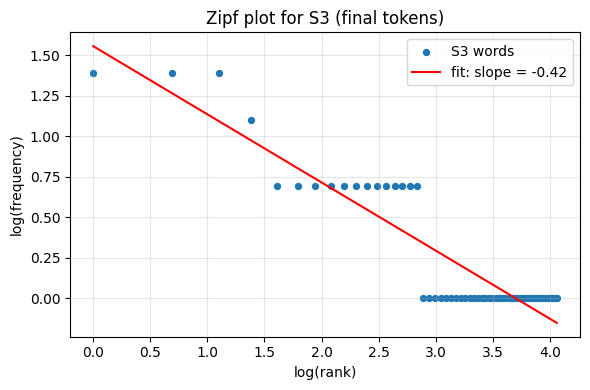


Top 5 bigrams of S1:
  (student, portal)  4
  (the, student)  3
  (., please)  3
  (keeps, asking)  2
  (asking, for)  2

Top 5 bigrams of S3:
  (student, portal)  4
  (keeps, asking)  2
  (asking, login)  2
  (n't, know)  2
  (know, changed)  2


In [9]:
import numpy as np
import matplotlib.pyplot as plt

S1 = [t for r in results.values() for t in r["tokens"]]          # all tokens
S2 = [t for t in S1 if not is_punct(t)]                          # no punctuation
S3 = [t for r in results.values() for t in r["final"]]           # final tokens
S4 = [porter.stem(t) for t in S3]                                # S3 after Porter

stats = pd.DataFrame(
    [(name, len(S), len(set(S)), len(set(S)) / len(S))
     for name, S in [("S1 all tokens", S1), ("S2 no punctuation", S2), ("S3 final tokens", S3), ("S4 S3 + Porter", S4)]],
    columns=["Set", "Total_Tokens", "Unique_Tokens", "TTR"])
stats["TTR"] = stats["TTR"].round(4)
display(stats)

print("\nTop 10 words of S1:")
for w, c in Counter(S1).most_common(10): print(f"  {w!r:12} {c}")
print("\nTop 10 words of S3:")
for w, c in Counter(S3).most_common(10): print(f"  {w!r:12} {c}")

# log(rank) vs log(frequency) for S3
freqs = sorted(Counter(S3).values(), reverse=True)
ranks = np.arange(1, len(freqs) + 1)
x, y = np.log(ranks), np.log(freqs)
slope, intercept = np.polyfit(x, y, 1)
plt.figure(figsize=(6, 4))
plt.scatter(x, y, s=18, label="S3 words")
plt.plot(x, slope * x + intercept, color="red", label=f"fit: slope = {slope:.2f}")
plt.xlabel("log(rank)"); plt.ylabel("log(frequency)")
plt.title("Zipf plot for S3 (final tokens)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# bigrams are counted inside each ticket so that no bigram spans two different tickets
def top_bigrams(key, n=5):
    c = Counter()
    for r in results.values():
        seq = r[key]
        c.update(zip(seq, seq[1:]))
    return c.most_common(n)

print("\nTop 5 bigrams of S1:")
for (a, b), c in top_bigrams("tokens"): print(f"  ({a}, {b})  {c}")
print("\nTop 5 bigrams of S3:")
for (a, b), c in top_bigrams("final"):  print(f"  ({a}, {b})  {c}")

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR = unique tokens / total tokens, so it rises when repeated tokens are removed and falls when distinct types are merged. **S1 to S2:** every ticket contains one or more full stops (plus commas, brackets, `?`, `!`), so punctuation is a large number of repeated tokens but only a few types; removing it shrinks the total much more than the unique count, so TTR goes up. **S2 to S3:** stopwords (*the, is, i, it, my, ...*) are the most repeated types in the data, so removing them raises TTR again. **S3 to S4:** the total stays the same but Porter merges inflected forms (e.g. *works/worked* to `work`, *pc/pcs* to `pc`), so the number of unique tokens drops and TTR falls slightly. In short, TTR increases from S1 to S3 and then decreases a little at S4; the table above shows the exact values.

---
## Q6. Interpretation

**(a) Why does TTR change from S1 to S4?**  
TTR = unique/total. From S1 to S3 the repeated tokens (punctuation, then stopwords) are deleted, so the total drops faster than the number of unique tokens and TTR rises. From S3 to S4 the total is unchanged but stemming merges inflected forms (*works/worked* to `work`, *pc/pcs* to `pc`), so unique tokens fall and TTR drops a little. (Exact values are in the Q5 table.)

**(b) One example where `word_tokenize()` and my tokenizer differ.**  
*"The Wi-Fi works, but the VPN doesn't."* (T10): `word_tokenize` returns `does` + `n't`, while `my_tokenize` returns `doesn't`. The Treebank tokenizer splits a contraction into a word and a clitic (useful for syntax and negation handling, but it leaves the stray token `n't`), while my pattern allows an apostrophe between letters and keeps the contraction as one token.

**(c) One example where stemming gives an undesirable result.**  
Porter stems *deadline* to `deadlin`, *reinstalled* to `reinstal` and *update* to `updat` - these are not words, so the stems are unreadable and cannot be looked up in a dictionary. Porter also reduces *computer* to `comput`, which would merge it with *computing* and *computation*.

**(d) One example where POS-aware lemmatization preserves meaning better than stemming.**  
For *deadline* (noun) the lemmatizer keeps `deadline`, while Porter gives `deadlin`. For verbs such as *locked* (VBN), *uploading* (VBG) and *keeps* (VBZ) the POS tag from `pos_tag` makes the lemmatizer return the real dictionary forms `lock`, `upload`, `keep`,. Without the POS tag WordNet would treat everything as a noun and leave *uploading* and *locked* unchanged, so the POS information is what makes the lemma correct.